# 05 · Espaço para crescer e próximos meses

Os notebooks anteriores mostraram que a Olist cresce (02), que o atraso derruba a nota e a recompra (03) e que o atraso se concentra no transporte para o Rio de Janeiro e o Nordeste (04). Um investidor pergunta o passo seguinte:

> **Onde ainda há espaço para crescer e o que esperar dos próximos meses?**

A primeira parte usa um **dado externo**: a população estimada de cada estado em 2018, do IBGE. A conta é simples: quantos pedidos a Olist faz para cada 100 mil habitantes. Onde esse número é baixo, há gente que ainda não compra.

## 8.1 Leitura dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

pedidos = pd.read_csv('../data/processed/pedidos.csv')
populacao = pd.read_csv('../data/external/populacao_uf_2018_ibge.csv')

print('Pedidos:', pedidos.shape)
print('Estados na tabela do IBGE:', populacao['uf'].nunique())
print(f"População total em 2018: {populacao['populacao_2018'].sum():,}")
populacao.head()

Pedidos: (99441, 31)
Estados na tabela do IBGE: 27
População total em 2018: 208,494,900


,uf,estado,regiao,populacao_2018
0,RO,Rondônia,Norte,1757589
1,AC,Acre,Norte,869265
2,AM,Amazonas,Norte,4080611
3,RR,Roraima,Norte,576568
4,PA,Pará,Norte,8513497


A tabela do IBGE tem os **27 estados** e soma **208,5 milhões** de pessoas, a estimativa oficial para 2018 (tabela 6579 do SIDRA). O ano está dentro do recorte da base (jan/2017 a ago/2018).

Para contar os pedidos, uso as regras do notebook 02: só o recorte e só vendas válidas (sem cancelados e indisponíveis). Para o atraso, só pedidos entregues, como no notebook 03.

In [2]:
vendas = pedidos[pedidos['no_recorte'] & pedidos['venda_valida']]
entregues = pedidos[pedidos['no_recorte'] & pedidos['entregue']]

por_uf = populacao.set_index('uf')
por_uf['pedidos'] = vendas.groupby('uf_cliente').size()
por_uf['pct_atraso'] = entregues.groupby('uf_cliente')['atrasado'].mean()
por_uf['pedidos_100mil_hab'] = por_uf['pedidos'] / por_uf['populacao_2018'] * 100_000

print(f"Pedidos válidos no recorte: {len(vendas):,}")
print('Estados sem pedidos:', por_uf['pedidos'].isna().sum())

Pedidos válidos no recorte: 97,905
Estados sem pedidos: 0


**97.905 pedidos** válidos, os mesmos do notebook 02, e todos os estados têm pedidos.

## 8.2 A Olist vende onde as pessoas estão?

**Hipótese:** se a Olist atendesse o país todo por igual, cada região teria nos pedidos a mesma participação que tem na população. Para testar, comparo as duas participações por região.

              pct_populacao  pct_pedidos  pedidos_100mil_hab  pct_atraso
regiao                                                                  
Sudeste               0.421        0.686              76.553       0.061
Nordeste              0.272        0.095              16.335       0.128
Sul                   0.143        0.142              46.874       0.059
Norte                 0.087        0.019              10.054       0.086
Centro-Oeste          0.077        0.058              35.509       0.065


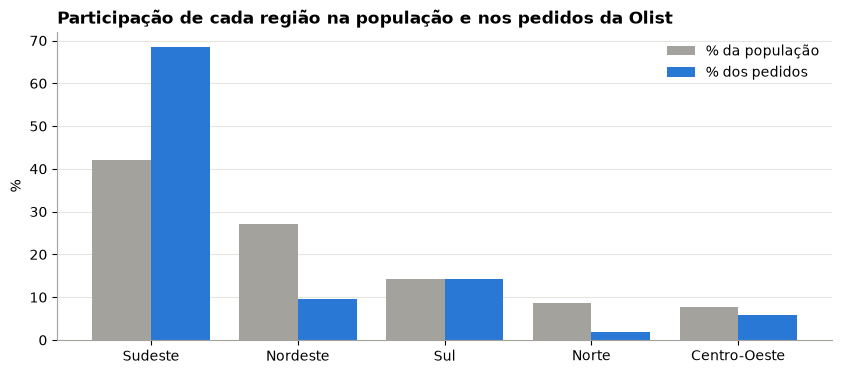

In [3]:
por_regiao = por_uf.groupby('regiao').agg(populacao=('populacao_2018', 'sum'), pedidos=('pedidos', 'sum'))
por_regiao['pct_populacao'] = por_regiao['populacao'] / por_regiao['populacao'].sum()
por_regiao['pct_pedidos'] = por_regiao['pedidos'] / por_regiao['pedidos'].sum()
por_regiao['pedidos_100mil_hab'] = por_regiao['pedidos'] / por_regiao['populacao'] * 100_000
regiao_entregues = entregues.merge(populacao[['uf', 'regiao']], left_on='uf_cliente', right_on='uf')
por_regiao['pct_atraso'] = regiao_entregues.groupby('regiao')['atrasado'].mean()
por_regiao = por_regiao.sort_values('pct_populacao', ascending=False)

print(por_regiao[['pct_populacao', 'pct_pedidos', 'pedidos_100mil_hab', 'pct_atraso']].round(3))

posicao = range(len(por_regiao))
plt.figure()
plt.bar([p - 0.2 for p in posicao], por_regiao['pct_populacao'] * 100, width=0.4, color=CINZA, label='% da população')
plt.bar([p + 0.2 for p in posicao], por_regiao['pct_pedidos'] * 100, width=0.4, color=AZUL, label='% dos pedidos')
plt.xticks(list(posicao), por_regiao.index)
plt.title('Participação de cada região na população e nos pedidos da Olist')
plt.ylabel('%')
plt.legend(frameon=False)
plt.show()

- O **Sudeste** tem 42% da população e **69% dos pedidos**: 77 pedidos por 100 mil habitantes.
- O **Sul** é a única região equilibrada (14% da população, 14% dos pedidos).
- O **Nordeste** tem **27% da população** e só **9,5% dos pedidos**: 16 pedidos por 100 mil habitantes, quase cinco vezes menos que o Sudeste. E é a região com **mais atraso: 12,8%**, o dobro do Sudeste (6,1%).
- O **Norte** compra ainda menos (10 por 100 mil habitantes), com atraso de 8,6%.

A hipótese não se sustenta: a Olist **não vende onde as pessoas estão**. O Nordeste, com 57 milhões de pessoas, é o maior grupo que quase não compra, e é também onde o serviço é pior.

## 8.3 Pedidos por habitante em cada estado

O mesmo olhar, agora por estado. Em laranja, os estados com atraso acima de 10% (o mesmo corte do notebook 04).

          regiao  pedidos  pedidos_100mil_hab  pct_atraso
uf                                                       
SP       Sudeste    41021              90.079       0.045
RJ       Sudeste    12654              73.741       0.121
DF  Centro-Oeste     2114              71.066       0.057
MG       Sudeste    11457              54.452       0.046
SC           Sul     3590              50.739       0.082
ES       Sudeste     2014              50.700       0.107
RS           Sul     5395              47.619       0.061
PR           Sul     4962              43.722       0.041
GO  Centro-Oeste     1990              28.752       0.066
MT  Centro-Oeste      900              26.148       0.060
MS  Centro-Oeste      708              25.764       0.097
BA      Nordeste     3340              22.548       0.122
TO         Norte      278              17.875       0.099
PE      Nordeste     1636              17.228       0.096
SE      Nordeste      342              15.011       0.154
PI      Nordes

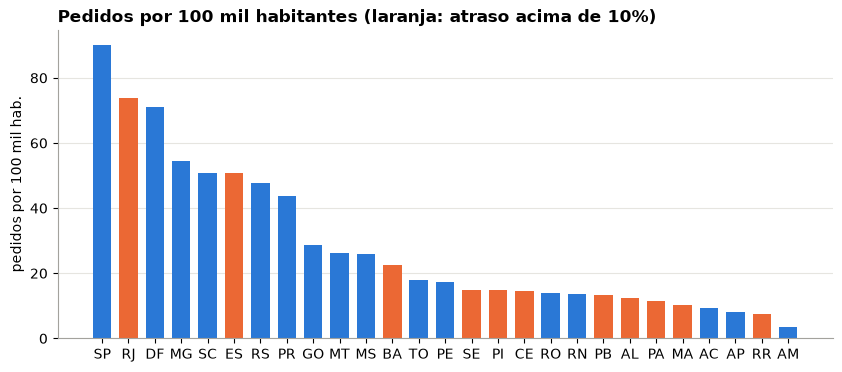

In [4]:
por_uf = por_uf.sort_values('pedidos_100mil_hab', ascending=False)
print(por_uf[['regiao', 'pedidos', 'pedidos_100mil_hab', 'pct_atraso']].round(3))

cores = [LARANJA if p > 0.10 else AZUL for p in por_uf['pct_atraso']]
plt.figure()
plt.bar(por_uf.index, por_uf['pedidos_100mil_hab'], color=cores, width=0.7)
plt.title('Pedidos por 100 mil habitantes (laranja: atraso acima de 10%)')
plt.ylabel('pedidos por 100 mil hab.')
plt.show()

- Os estados que mais compram por habitante são **SP (90)**, **RJ (74)** e **DF (71)**.
- No fim da lista estão os estados do **Norte e do Nordeste**: o Maranhão faz 10 pedidos por 100 mil habitantes e atrasa 17,5%; Alagoas, 12 e 21,5%.
- **Cuidado com a conclusão:** comprar pouco não é só efeito do atraso. O Amazonas compra menos que todos (3,6) e quase não atrasa (2,8%); o Rio de Janeiro compra muito e atrasa 12%. Renda, acesso à internet e distância dos vendedores também pesam, e a base não permite separar essas causas.

**O que dá para afirmar:** o Nordeste é o maior mercado pouco atendido pela Olist e é onde a entrega mais falha. Como o notebook 03 mostrou que o atraso derruba a nota e a recompra, **crescer no Nordeste sem corrigir a logística seria trazer clientes para uma experiência ruim**. Corrigir as rotas para o Nordeste é condição para crescer lá.